# Heatwave Analysis of Indian Cities (2020 - 2025)

## 1. Data Imports

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb

sb.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = Path("../data/final_dataset.csv")
PROCESSED_DIR = Path("../data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
raw_data = pd.read_csv(DATA_PATH, parse_dates = ["date"])

print(f"Rows: {len(raw_data):,} | States: {raw_data['state'].nunique()} | "
     f"Dates: {raw_data['date'].min().date()} to {raw_data['date'].max().date()}")
raw_data.head()
raw_data.dtypes

Rows: 105,980 | States: 28 | Dates: 2014-01-08 to 2024-04-28


date             datetime64[ns]
state                    object
tmax                    float64
tmin                    float64
humidity                float64
heat_index              float64
hot_day                   int64
hot_night                 int64
peak_met_mw             float64
peak_unmet_mw           float64
dtype: object

## 2. Checking for missing values

In [3]:
full_calendar = pd.date_range(raw_data["date"].min(), raw_data["date"].max(), freq="D")
dup_mask = raw_data.duplicated(["state", "date"], keep=False)
exact_dup = raw_data.duplicated(keep=False)

audit = pd.Series({
    "duplicate state rows(extra copies)": int(raw_data.duplicated(['state', 'date']). sum()),
    "rows in conflicting duplicate groups": int((dup_mask & ~exact_dup).sum()),
    "calendar days missing (all states)": int(len(full_calendar) - raw_data['date'].nunique()),
    "missing peak_met_mw": int(raw_data['peak_met_mw'].isna().sum()),
    "missing peak_unmet_mw": int(raw_data['peak_unmet_mw'].isna().sum()),
    "zero peak_met_mw": int((raw_data['peak_met_mw'] == 0).sum()),
    "negative peak_unmet_mw": int((raw_data['peak_unmet_mw'] < 0).sum()),
    "share of days with zero unmet demand": round(float((raw_data['peak_unmet_mw'] == 0).mean()), 3)
})

audit.to_frame("count / value")
# print(full_calendar)
# print(dup_mask)
# print(exact_dup)


,count / value
duplicate state rows(extra copies),4368.000
rows in conflicting duplicate groups,248.000
calendar days missing (all states),135.000
missing peak_met_mw,160.000
missing peak_unmet_mw,175.000
zero peak_met_mw,3.000
negative peak_unmet_mw,66.000
share of days with zero unmet demand,0.734


In [4]:
WEATHER_COLS = ["tmax", "tmin", "humidity", "heat_index"]
INTERP_LIMIT = 3

# 1. De-duplicate
agg = {c: "first" for c in WEATHER_COLS + ["hot_day", "hot_night"]}
agg.update({"peak_met_mw": "max", "peak_unmet_mw": "max"})
df = raw_data.groupby(['state', 'date'], as_index = False).agg(agg)

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())

# 2. Re-index to a complete daily calendar per state
idx = pd.MultiIndex.from_product([sorted(df['state']. unique()), full_calendar], names = ['state', 'date'])
df = df.set_index(['state', 'date']).reindex(idx).reset_index()

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())


# # 3. Fixing bad values
df.loc[df['peak_met_mw'] <= 0, 'peak_met_mw'] = np.nan
df.loc[df['peak_unmet_mw'] < 0, 'peak_unmet_mw'] = 0

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())


# # 4. Interpolate short gaps only: gaps of up to 3 days are filled, longer gaps stay missing.
# #    (pandas limit = 3 will fill the first 3 days of a long gap; the longer gaps beyond this will be masked to NaN)

def fill_short_gaps(s, max_gap = INTERP_LIMIT):
    isna = s.isna()
    run_id = isna.ne(isna.shift()).cumsum()
    run_len = isna.groupby(run_id).transform("sum")
    filled = s.interpolate(limit_area = "inside")
    return filled.mask(isna & (run_len > max_gap))

num_cols = WEATHER_COLS + ['peak_met_mw', 'peak_unmet_mw']
df = df.sort_values(['state', 'date'])

#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())


for c in num_cols:
    df[c] = df.groupby('state')[c].transform(fill_short_gaps)
    
#print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())

    
# 5. Re-compute heat flags from definitions
# Assumption: A day is considered hot if the max temp is GREATER than 40 degrees.
#             A night is considered hot if the min temp is GREATER than 30 degrees.

df['hot_day'] = (df['tmax'] >= 40).astype(int)
df['hot_night'] = (df['tmin'] >= 30).astype(int)

# # 6. Build the target and drop rows which can't be used
df['peak_demand_mw'] = df['peak_met_mw'] + df['peak_unmet_mw'].fillna(0)
split_noise = df['state'].isin(["ANDHRA PRADESH", "TELANGANA"]) & (df['date'] < "2015-01-01")
df = df[~split_noise].dropna(subset = ['peak_met_mw'] + WEATHER_COLS).reset_index(drop = True)

print(df["state"].nunique(), df["state"].isin(["ANDHRA PRADESH", "TELANGANA"]).sum())

assert df[num_cols].isna().sum().sum() == 0
assert not df.duplicated(['state', 'date']).any()
print(f"Clean rows: {len(df):,} (from {len(raw_data):,}) raw")

28 6720
Clean rows: 103,388 (from 105,980) raw


In [5]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

# Demand relative to each state's own 1-year rolling level: removes the growth trend
# so that seasonal and temperature effects are comparable across states and years.

df['demand_level'] = df.groupby('state')['peak_demand_mw'].transform(
lambda s: s.rolling(365, center = True, min_periods = 180).mean())
df['demand_ratio'] = df['peak_demand_mw'] / df['demand_level']

df.to_csv(PROCESSED_DIR / "clean_daily.csv", index = False)
df.describe().T[['count', 'mean', 'min', 'max']].round(2)


,count,mean,min,max
tmax,103388.0,29.24,-3.46,48.77
tmin,103388.0,19.02,-14.39,35.93
humidity,103388.0,66.81,5.32,100.00
heat_index,103388.0,35.71,15.09,84.62
hot_day,103388.0,0.06,0.00,1.00
hot_night,103388.0,0.01,0.00,1.00
peak_met_mw,103388.0,5685.54,21.00,28969.00
peak_unmet_mw,103388.0,45.98,0.00,6120.00
peak_demand_mw,103388.0,5731.53,21.00,30982.00
year,103388.0,2018.71,2014.00,2024.00


## 3. Exploratory Analysis

### 3.1 Steady growth in demand

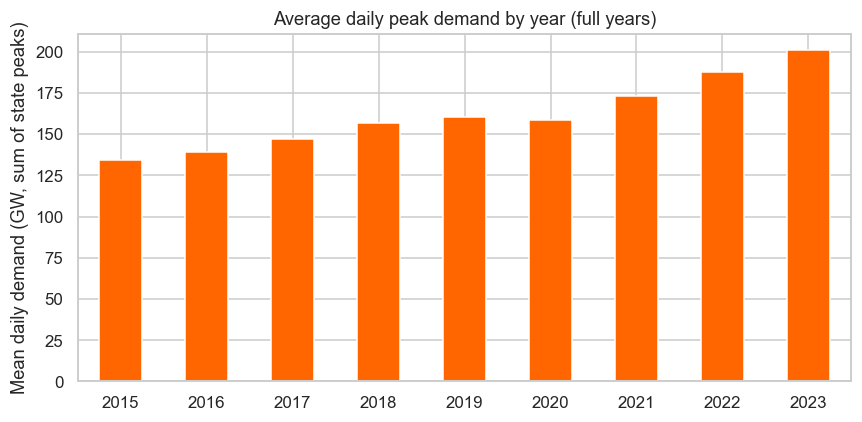

Growth 2015 to 2023:  49%


In [6]:
national = df.groupby('date')['peak_demand_mw'].sum().rename('total_mw').reset_index()
national['year'] = national['date'].dt.year
annual = national.groupby('year')['total_mw'].mean() / 1000
annual = annual.loc[2015:2023] #full years only (2014 lacks AP/Telangana, 2024 is partial)
# national.head(40)
# national.tail(40)
fig, ax = plt.subplots(figsize = (8,4))
annual.plot(kind = "bar", ax = ax, color = "#ff6600")
ax.set_ylabel("Mean daily demand (GW, sum of state peaks)")
ax.set_xlabel("")
ax.set_title("Average daily peak demand by year (full years)")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()
print(f"Growth {annual.index[0]} to {annual.index[-1]}: {annual.iloc[-1] / annual.iloc[0] - 1: .0%}")

### 3.2 Temperature & Demand

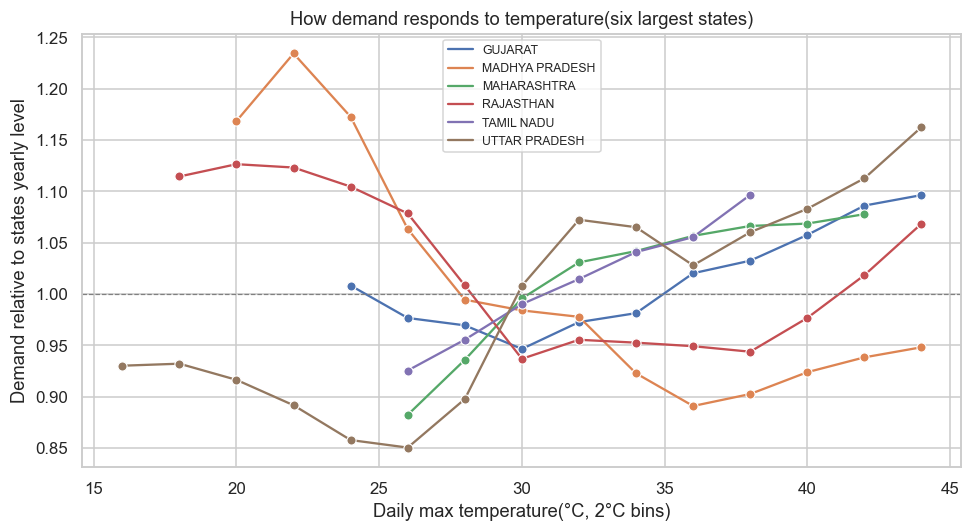

In [7]:
top_states = df.groupby('state')['peak_demand_mw'].mean().nlargest(6).index
sub = df[df['state'].isin(top_states)].copy()
sub['tmax_bin'] = (sub['tmax'] // 2*2).clip(lower = 14, upper = 44)

binned = (sub.groupby(['state', 'tmax_bin'])['demand_ratio']
         .agg(['mean', 'count']).reset_index())
binned = binned[binned['count'] >= 20]

fig, ax = plt.subplots(figsize = (9, 5))
sb.lineplot(data = binned, x = 'tmax_bin', y = 'mean', hue = 'state', marker = 'o', ax = ax)
ax.axhline(1, color = 'grey', lw = 0.8, ls = '--')
ax.set_xlabel("Daily max temperature(°C, 2°C bins)")
ax.set_ylabel("Demand relative to states yearly level")
ax.set_title("How demand responds to temperature(six largest states)")
ax.legend(title = "", fontsize = 8)
plt.tight_layout()
plt.show()

### 3.3 Seasonality: Finding which months are the demand peaks.

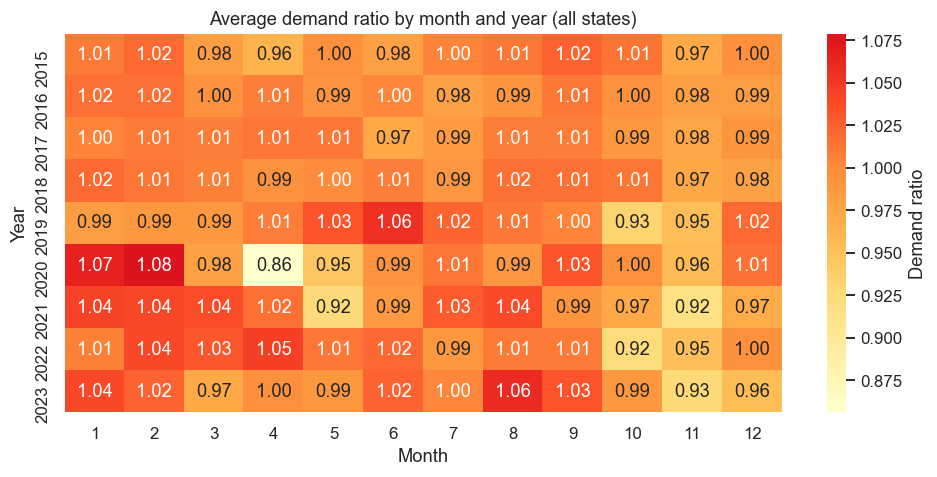

In [8]:
nat_ratio = (df.groupby(['year', 'month'])['demand_ratio'].mean().unstack('month'))
nat_ratio = nat_ratio.loc[2015:2023]

fig, ax = plt.subplots(figsize = (9, 4.5))
sb.heatmap(nat_ratio, cmap = "YlOrRd", center = 1, annot = True, fmt = ".2f", cbar_kws = {"label": "Demand ratio"}, ax = ax)
ax.set_xlabel("Month")
ax.set_ylabel("Year")
ax.set_title("Average demand ratio by month and year (all states)")
plt.tight_layout()
plt.show()

### 3.4 Determining whether hot days affect the demand

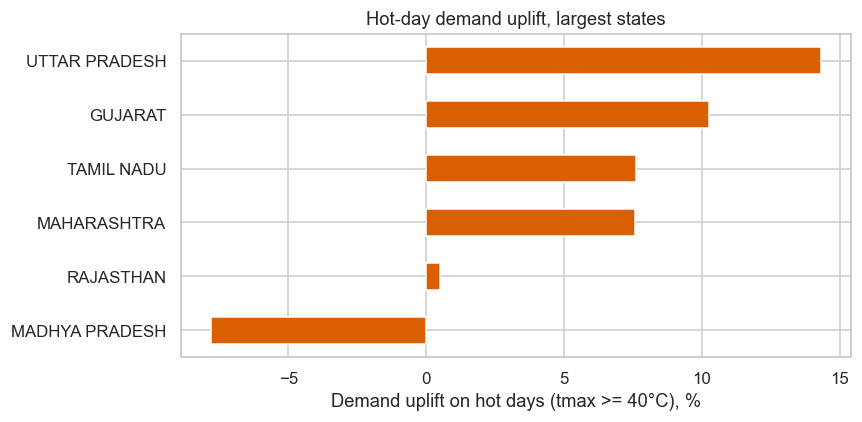

,normal_day,hot_day,uplift_pct
state,,,
GUJARAT,0.979,1.080,10.264
MADHYA PRADESH,1.012,0.933,-7.790
MAHARASHTRA,0.995,1.071,7.586
RAJASTHAN,1.000,1.005,0.519
TAMIL NADU,1.000,1.077,7.624
UTTAR PRADESH,0.975,1.114,14.319


In [9]:
effect = (df[df['state'].isin(top_states)]
          .groupby(['state', 'hot_day'])['demand_ratio'].mean().unstack('hot_day'))
effect.columns = ['normal_day', 'hot_day']
effect['uplift_pct'] = (effect['hot_day'] / effect['normal_day'] - 1) * 100

fig, ax = plt.subplots(figsize = (8,4))
effect['uplift_pct'].sort_values().plot(kind = 'barh', ax = ax, color = "#d95f02")
ax.set_xlabel("Demand uplift on hot days (tmax >= 40°C), %")
ax.set_ylabel("")
ax.set_title("Hot-day demand uplift, largest states")
plt.tight_layout()
plt.show()
effect.round(3)

### 3.5 Unmet demand

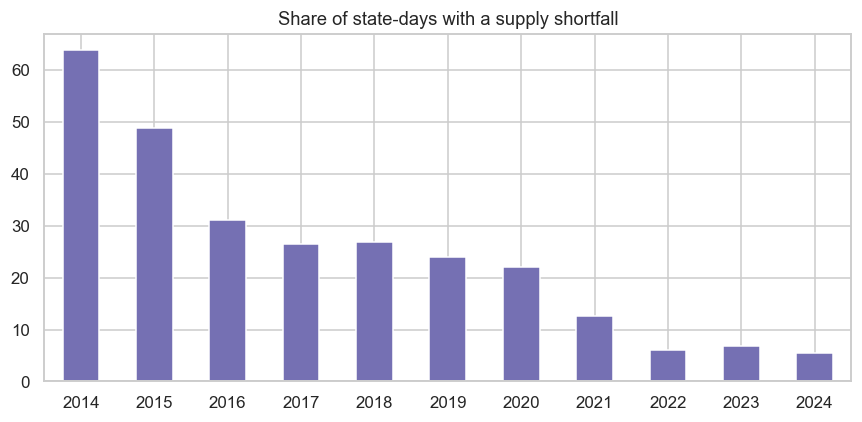

Average daily unmet peak(MW), top 5 states:
state
UTTAR PRADESH    634.0
KARNATAKA        135.0
TAMIL NADU        95.0
ASSAM             63.0
BIHAR             61.0


In [10]:
shortfall = (df.assign(short_day = df['peak_unmet_mw'] > 0)
            .groupby('year')['short_day'].mean() * 100)

fig,ax = plt.subplots(figsize = (8,4))
shortfall.plot(kind = "bar", ax = ax, color = "#7570b3")
ax.set_xlabel("% of state-days with unmet demand")
ax.set_xlabel("")
ax.set_title("Share of state-days with a supply shortfall")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

top_unmet = df.groupby('state')['peak_unmet_mw'].mean().nlargest(5).round(0)
print("Average daily unmet peak(MW), top 5 states:")
print(top_unmet.to_string())